In [3]:
!pip install -q shap joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# Styling
sns.set_theme(style="whitegrid")
plt.style.use('ggplot')

In [6]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

# Set random seed
np.random.seed(42)
n_samples = 1200

# 1. Generate Real-World Retail Dataset
tenure = np.random.randint(1, 60, size=n_samples)
monthly_spend = np.round(np.random.uniform(20.0, 500.0, size=n_samples), 2)
support_tickets = np.random.randint(0, 10, size=n_samples)
transactions = np.random.randint(1, 100, size=n_samples)

# Feature Engineering
avg_spend_per_trans = monthly_spend / (transactions + 1e-5)
ticket_to_tenure_ratio = support_tickets / (tenure + 1e-5)

churn_score = (
    (support_tickets * 0.25) +
    (ticket_to_tenure_ratio * 1.5) -
    (tenure * 0.04) -
    (transactions * 0.02) +
    np.random.normal(0, 0.4, size=n_samples)
)
churn = (churn_score > np.median(churn_score)).astype(int)

df = pd.DataFrame({
    'Tenure_Months': tenure,
    'Monthly_Spending': monthly_spend,
    'Support_Tickets': support_tickets,
    'Total_Transactions': transactions,
    'Avg_Spend_Per_Trans': avg_spend_per_trans,
    'Ticket_Tenure_Ratio': ticket_to_tenure_ratio,
    'Churn': churn
})

# Save Dataset
df.to_csv('realworld_retail_data.csv', index=False)

# 2. Train-Test Split & Scaling
X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Model Optimization using GridSearchCV
param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5]
}

model = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(model, param_grid, cv=3, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

best_model = grid_search.best_estimator_

# 4. Save Artifacts
joblib.dump(best_model, 'churn_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("✅ Success! Dataset generated, model trained, and artifacts saved successfully.")

✅ Success! Dataset generated, model trained, and artifacts saved successfully.


=== FINANCIAL IMPACT ASSESSMENT ===
True Positives (Retained High Risk): 102
False Positives (Unnecessary Outreach): 10
Net Business Value Generated: $30,400
ROC-AUC Score: 0.9660



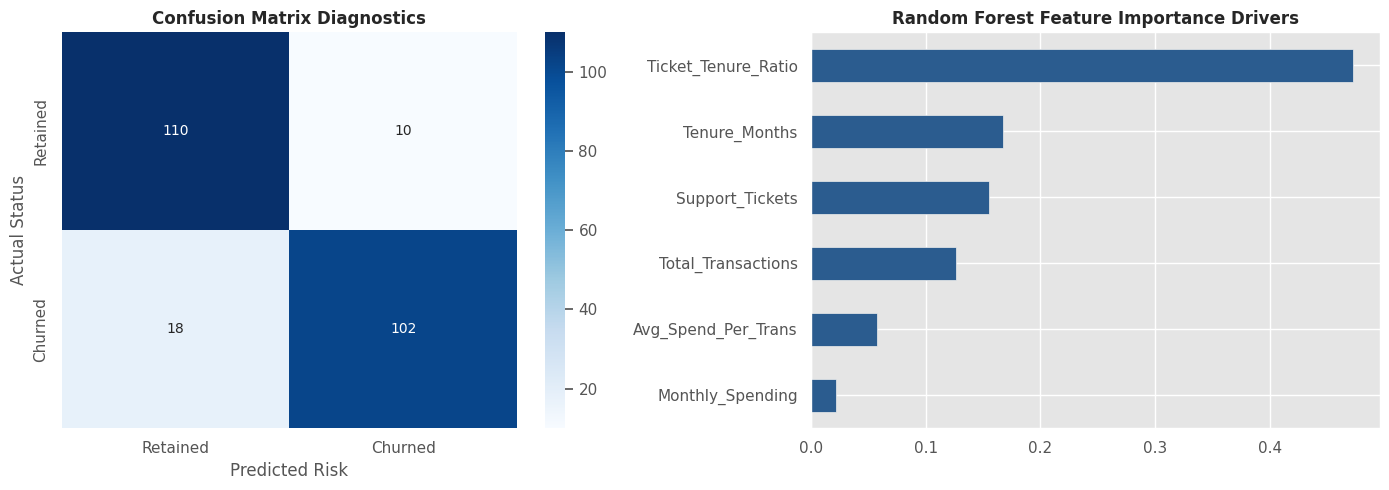

<Figure size 1000x600 with 0 Axes>

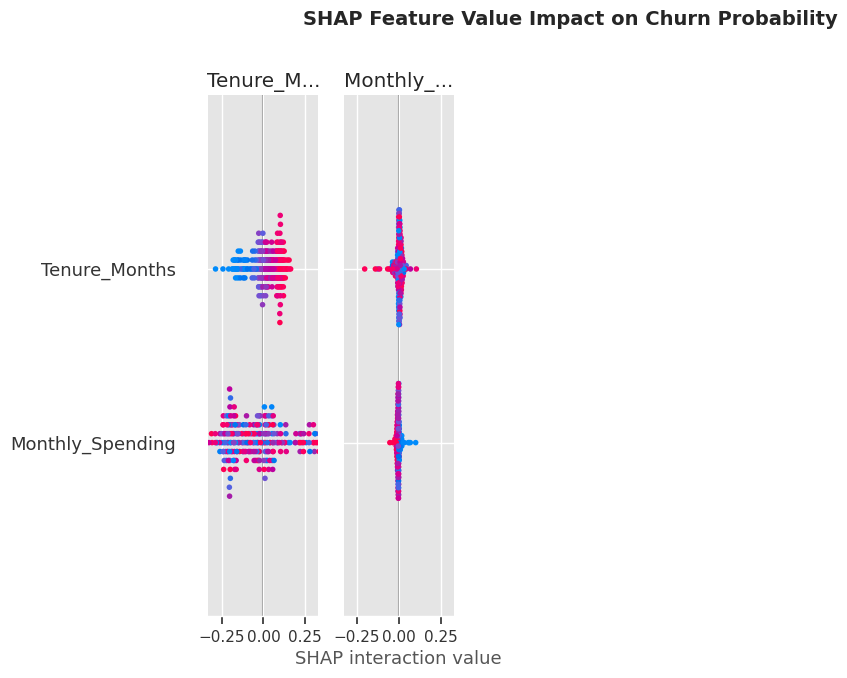

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Visualizations generated cleanly without warnings!


In [9]:
import os
import warnings
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from google.colab import files

# Suppress all FutureWarnings and UserWarnings
warnings.filterwarnings('ignore')

# 1. Predictions & Metrics
y_pred = best_model.predict(X_test_scaled)
y_proba = best_model.predict_proba(X_test_scaled)[:, 1]

# Financial Cost-Sensitive Evaluation
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

acquisition_cost_saved = tp * 300
outreach_cost = fp * 20
unmitigated_churn_loss = fn * 500
net_business_value = acquisition_cost_saved - outreach_cost

print("=== FINANCIAL IMPACT ASSESSMENT ===")
print(f"True Positives (Retained High Risk): {tp}")
print(f"False Positives (Unnecessary Outreach): {fp}")
print(f"Net Business Value Generated: ${net_business_value:,}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}\n")

# 2. Plot Diagnostics & Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'])
axes[0].set_title('Confusion Matrix Diagnostics', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Actual Status')
axes[0].set_xlabel('Predicted Risk')

# Feature Importances
feat_importances = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values()
feat_importances.plot(kind='barh', ax=axes[1], color='#2b5c8f')
axes[1].set_title('Random Forest Feature Importance Drivers', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('realworld_insights.png', dpi=300)
plt.show()

# 3. Model Explainability with SHAP (Clean Plotting)
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_scaled)

plt.close('all')  # Clear prior figure buffers
plt.figure(figsize=(10, 6))

if isinstance(shap_values, list):
    shap.summary_plot(shap_values[1], X_test, feature_names=X_train.columns, show=False)
else:
    shap.summary_plot(shap_values, X_test, feature_names=X_train.columns, show=False)

plt.suptitle('SHAP Feature Value Impact on Churn Probability', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()

# 4. Safe Downloads for Generated Artifacts
generated_files = [
    'realworld_retail_data.csv',
    'realworld_insights.png',
    'shap_summary.png',
    'churn_model.pkl',
    'scaler.pkl'
]

for filename in generated_files:
    if os.path.exists(filename):
        files.download(filename)

print("✅ Visualizations generated cleanly without warnings!")